In [1]:
import sys
sys.path.append('../src')
from circuit_template import *
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from matplotlib.animation import FuncAnimation

In [2]:
V_MAX = 30
n = 20
circuit = make_stadium()
veh = place_vehicles(circuit, n, layout="random")
veh["v"] = np.random.default_rng(1).uniform(10, V_MAX, len(veh["s"]))
print(f"Longueur du circuit : {circuit.L:.0f} m, rayon minimal : {circuit.min_radius():.0f} m, " + f"{len(veh['s'])} véhicules")

Longueur du circuit : 977 m, rayon minimal : 52 m, 80 véhicules


In [3]:
print_neighbours_table(veh, circuit.L)

,sens,voie,s [m],v [m/s],leader,gap avant [m],suiveur,gap arrière [m],leader autre voie,gap autre voie [m]
i,,,,,,,,,,
0,1,0,30.0,20.2,1,13.5,19,58.6,35,11.4
1,1,0,48.5,29.0,2,16.3,0,13.5,36,140.5
2,1,0,69.8,12.9,3,8.2,1,16.3,36,119.2
3,1,0,83.0,29.0,4,114.7,2,8.2,36,106.0
4,1,0,202.7,16.2,5,80.8,3,114.7,37,30.6
5,1,0,288.5,18.5,6,27.0,4,80.8,39,11.7
6,1,0,320.5,26.6,7,104.9,5,27.0,20,93.0
7,1,0,430.5,18.2,8,101.4,6,104.9,21,-0.9
8,1,0,536.9,21.0,9,3.8,7,101.4,22,46.3


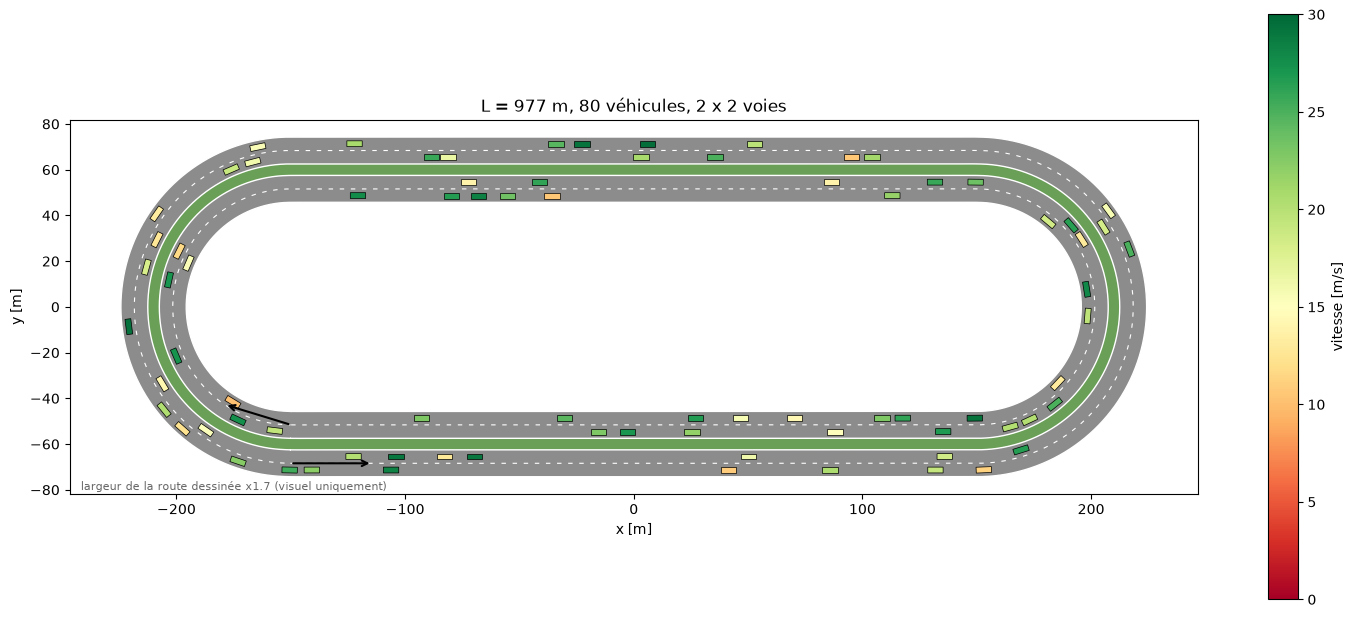

In [4]:
zoom = None

plot_state(circuit, veh, color_by="speed", zoom=zoom, label_cars=zoom is not None)
plt.tight_layout()
plt.show()

In [5]:
params = {"v0": 30.0, "T": 1.5, "s0": 2.0}
dt = 0.1

In [6]:
a = acceleration(np.array([20., 100., 1000.]), np.array([20., 20., 10.]),
                 np.array([-20., 0., 0.]), params)
print(a)    # attendu : [-18.67  6.67  13.33]

None


In [3]:
# C1 : suiveur à 30 m/s, à 5 m d'un leader arrêté (le leader est le véhicule d'abscisse 110)
s, v = np.array([100., 110.]), np.array([30., 0.])
for k in range(10):
    s, v, info = step(s, v, dt, circuit, params)
    if len(info["impacts"]):
        print("C1 impact au pas", k, ":", info["impacts"], "| gap après :", s[1] - s[0] - VEH_LENGTH, "| vitesses :", v)
        break
# attendu : impact au pas 1, vitesse relative ~27.6 m/s, gap après = 0, les deux véhicules à la même vitesse

# C2 : cascade. Leader arrêté en tête, deux suiveurs lancés à 30 m/s
s, v = np.array([100., 90., 80.]), np.array([0., 30., 30.])
n, gap_min = 0, np.inf
for k in range(10):
    s, v, info = step(s, v, dt, circuit, params)
    n += len(info["impacts"])
    gap_min = min(gap_min, s[0] - s[1] - VEH_LENGTH, s[1] - s[2] - VEH_LENGTH)
print("C2 collisions :", n, "| aucun gap négatif :", gap_min >= -1e-9)
# attendu : 2 collisions (une par suiveur), et jamais de gap négatif

# C3 : limites physiques
_, _, info = step(np.array([100., 110.]), np.array([20., 0.]), dt, circuit, params)
print("C3 freinage : a_eff =", info["a_eff"][0], "| saturé :", info["sat"][0])   # attendu : -9.0, True
_, v, info = step(np.array([100., 105.]), np.array([0., 0.]), dt, circuit, params)
print("C3 à l'arrêt : a_eff =", info["a_eff"][0], "| v =", v[0])                   # attendu : 0.0, 0.0

NameError: name 'np' is not defined

In [4]:
# On ne garde qu'UNE file du template : sens +1, voie 0 (20 véhicules)
masque = (veh["direction"] == 1) & (veh["lane"] == 0)
s = veh["s"][masque].copy()
v = np.random.default_rng(1).uniform(10, 30, len(s))   # vitesses initiales aléatoires, comme le template

n_coll, a_min = 0, 0.0
s_hist, v_hist = [], []
for k in range(int(100 / dt)):
    s, v, info = step(s, v, dt, circuit, params)
    n_coll += len(info["impacts"]); a_min = min(a_min, info["a_eff"].min())
    if k % 10 == 0:                              # 1 image par seconde simulée
        s_hist.append(s.copy()); v_hist.append(v.copy())
print(f"collisions : {n_coll} | Dmax : {-a_min:.2f} m/s² | v moyenne finale : {v.mean():.1f} m/s")

NameError: name 'veh' is not defined

In [5]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

frame_state = {"s": s_hist[0], "v": v_hist[0],
               "lane": np.zeros(len(s_hist[0]), int), "direction": np.ones(len(s_hist[0]), int)}

fig, ax = plt.subplots(figsize=(13, 6), dpi=90)

def update(i):
    frame_state["s"], frame_state["v"] = s_hist[i], v_hist[i]
    plot_state(circuit, frame_state, color_by="speed", ax=ax, title=f"t = {i} s")
    fig.tight_layout()

anim = FuncAnimation(fig, update, frames=range(0, 60, 2), interval=150)
plt.close(fig)
HTML(anim.to_jshtml())

NameError: name 's_hist' is not defined

In [6]:
circ = make_circle(230.0); N = 22
rng = np.random.default_rng(0)
s = np.mod(np.linspace(0, circ.L, N, endpoint=False) + rng.uniform(-1, 1, N), circ.L)
v = np.zeros(N)
x = np.zeros(N)                                  # position non repliée (pour le débit Q)
n_coll = 0
for k in range(int(600 / dt)):
    s, v, info = step(s, v, dt, circ, params)
    x += info["dist"]; n_coll += len(info["impacts"])
print("collisions :", n_coll, "| v finale :", v.mean().round(2))   # attendu : 0 et ~2.30

NameError: name 'make_circle' is not defined